# Search probability $P({\bf x}_0, t)$: MCX-cascade shift operator

Flip-flop quantum walk search on a $32\times32$ periodic square lattice ($N=1024$); the circuit result is compared with the exact simulation. The three notebooks (QFT, ripple-carry, MCX cascade) differ only in the $\pm1$ implementation of the shift operator (Sec. 1).

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from classiq import *
from classiq.interface.exceptions import ClassiqAPIError

L = 32                      # lattice size per axis (N = L^2 = 1024)
NX = int(np.log2(L))        # qubits per axis
MARKED = (L // 2, L // 2)   # marked vertex
T_LIST = range(0, 121, 30)  # steps evaluated with the circuit
T_MAX = 120                 # steps for the exact simulation
SHOTS = 1000                # shots

CSV = "search_probability_mcx.csv"
PNG = "search_probability_mcx.png"
COLOR = "#1baf7a"

## 1. Shift operator $\pm1$: MCX cascade (Sahu & Sen)

$+1$ is a cascade of multi-controlled NOT gates: bit $p_k$ flips when the flag and $p_0,\dots,p_{k-1}$ are all 1, applied from the most significant bit. No ancilla qubits are used. $-1$ is the inverse of $+1$.

In [2]:
@qperm
def increment(flag: Const[QBit], p: QArray[QBit, NX]):
    """p -> p + 1 (mod L) if flag = 1. Multi-controlled NOTs from the most significant bit."""
    for k in range(NX - 1, 0, -1):
        control(flag, lambda: control(p[0:k], lambda: X(p[k])))
    CX(flag, p[0])


def decrement(flag, p):
    """p -> p - 1 (mod L) if flag = 1. Inverse of increment."""
    invert(lambda: increment(flag, p))

## 2. Quantum walk search circuit

One step: oracle $\to$ Grover coin $\to$ flip-flop shift.

In [3]:
class Position(QStruct):
    x: QNum[NX]
    y: QNum[NX]


@qperm
def oracle(pos: Const[Position]):
    """Phase flip on the marked vertex."""
    control((pos.x == MARKED[0]) & (pos.y == MARKED[1]), lambda: phase(np.pi))


@qperm
def flip(coin: QArray):
    X(coin[0])


def move_if(coin, value, op):
    """Apply op only if coin == value (the condition is computed into a temporary flag qubit)."""
    flag = QBit(f"flag{value}")
    within_apply(lambda: assign(coin == value, flag), lambda: op(flag))


@qfunc
def shift(pos: Position, coin: QNum):
    """Flip-flop shift: move one step according to the coin, then flip the coin."""
    move_if(coin, 0, lambda f: decrement(f, pos.x))                  # x - 1
    move_if(coin, 1, lambda f: increment(f, pos.x))                  # x + 1
    move_if(coin, 2, lambda f: decrement(f, pos.y))                  # y - 1
    move_if(coin, 3, lambda f: increment(f, pos.y))                  # y + 1
    flip(coin)


def build_model(t):
    """Uniform superposition followed by t steps of (oracle -> Grover coin -> shift)."""

    @qfunc
    def main(pos: Output[Position]):
        coin = QNum()
        allocate(pos)
        allocate(2, coin)
        hadamard_transform(pos)
        hadamard_transform(coin)
        power(t, lambda: [
            oracle(pos),
            grover_diffuser(lambda psi: hadamard_transform(psi), coin),
            shift(pos, coin),
        ])
        drop(coin)

    return create_model(main)

## 3. Circuit simulation

The circuit is synthesized and sampled for $t = 0, 30, 60, 90, 120$; $P({\bf x}_0)$ is the fraction of shots at the marked vertex.

In [4]:
def marked_probability(t):
    """Fraction of shots at the marked vertex after t steps."""
    qprog = synthesize(build_model(t))
    with ExecutionSession(qprog, execution_preferences=ExecutionPreferences(num_shots=SHOTS)) as es:
        res = es.sample()
    counts = res.dataframe
    hits = counts[(counts["pos.x"] == MARKED[0]) & (counts["pos.y"] == MARKED[1])]["counts"].sum()
    return hits / SHOTS


def with_retry(f, *args, retries=5, wait_sec=60):
    """Retry after a wait if the API call fails (e.g., HTTP 429)."""
    for attempt in range(retries):
        try:
            return f(*args)
        except ClassiqAPIError as err:
            print(f"API error ({err}); retry {attempt + 1}/{retries} after {wait_sec} s")
            time.sleep(wait_sec)
    return f(*args)


rows = []
for t in T_LIST:
    rows.append({"t": t, "P": with_retry(marked_probability, t)})
    print(rows[-1])
df = pd.DataFrame(rows)
df.to_csv(CSV, index=False)
df

{'t': 0, 'P': np.float64(0.002)}


{'t': 30, 'P': np.float64(0.102)}


{'t': 60, 'P': np.float64(0.189)}


{'t': 90, 'P': np.float64(0.048)}


{'t': 120, 'P': np.float64(0.021)}


,t,P
0,0,0.002
1,30,0.102
2,60,0.189
3,90,0.048
4,120,0.021


## 4. Exact simulation

In [5]:
GROVER = 2 * np.ones((4, 4)) / 4 - np.eye(4)


def exact_probability(T):
    """Exact P(x0, t) for t = 0, ..., T (the same walk computed with numpy)."""
    psi = np.ones((L, L, 4), dtype=complex) / np.sqrt(4 * L * L)
    probs = [np.sum(np.abs(psi[MARKED]) ** 2)]
    for _ in range(T):
        psi[MARKED] *= -1                                   # oracle
        psi = np.einsum("ab,xyb->xya", GROVER, psi)         # Grover coin
        new = np.zeros_like(psi)                            # flip-flop shift
        new[:, :, 1] += np.roll(psi[:, :, 0], -1, 0)
        new[:, :, 0] += np.roll(psi[:, :, 1], 1, 0)
        new[:, :, 3] += np.roll(psi[:, :, 2], -1, 1)
        new[:, :, 2] += np.roll(psi[:, :, 3], 1, 1)
        psi = new
        probs.append(np.sum(np.abs(psi[MARKED]) ** 2))
    return np.array(probs)


P_exact = exact_probability(T_MAX)
df["P_exact"] = P_exact[df["t"]]
df

,t,P,P_exact
0,0,0.002,0.000977
1,30,0.102,0.111497
2,60,0.189,0.202117
3,90,0.048,0.060843
4,120,0.021,0.017617


## 5. Plot

This cell uses the saved CSV, so Sec. 3 does not need to be run.

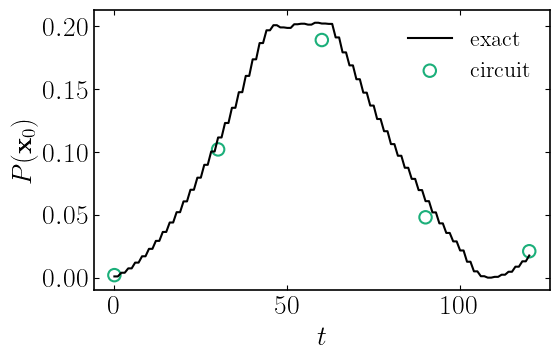

In [6]:
df = pd.read_csv(CSV)  # load the saved circuit results

plt.rcParams.update({"font.size": 20, "text.usetex": True, "font.family": "serif", "axes.linewidth": 1.2})
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(T_MAX + 1), exact_probability(T_MAX), color="black", lw=1.5, label="exact")
ax.scatter(df["t"], df["P"], s=80, facecolors="none", edgecolors=COLOR, linewidths=1.5, label="circuit")
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$P({\bf x}_0)$")
ax.tick_params(which="both", top=True, right=True, direction="in")
ax.legend(frameon=False, fontsize=16)
fig.tight_layout()
fig.savefig(PNG, dpi=200)
plt.show()